# QPSK 链路仿真与 BER 曲线

从自己生成的 0/1 出发，把每两个比特映射成一个 QPSK 符号，在信道里加噪，判决回比特，再用错误数画 BER 曲线。

先完成[第一周终端与环境练习](../../docs/adr-qpsk.md#第-1-周从终端开始)。打开后，在 **Kernel** 菜单里重启内核并运行全部单元，或从上到下用 **Shift + Enter** 逐格运行。代码里的循环和函数与 C++ 思路相同，`def` 定义函数，缩进标记代码块，NumPy 可以对整个数组一次做运算。

本实验使用复基带模型，每个符号用一个复数 $I+jQ$ 表示。假设发送端和接收端已同步，信道只有加性白高斯噪声（AWGN）。模型从比特覆盖到判决和统计，省略了成形滤波、过采样、同步、衰落和纠错编码。

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.special import erfc

SEED = 2026
N_BITS = 400_000  # 每个信噪比点的比特数，QPSK 需要偶数
EB_N0_DB = np.arange(0, 13, 1)
SYMBOL_ENERGY = 1.0
BIT_ENERGY = SYMBOL_ENERGY / 2
AMPLITUDE = np.sqrt(BIT_ENERGY)

plt.rcParams.update({"figure.dpi": 120, "font.size": 11})

## 1. 用四组比特验证映射与判决

第一个比特决定 $I$ 的正负，第二个决定 $Q$ 的正负。两个维度都用 0 表示正，1 表示负。按逆时针看，标签依次是 `00 → 10 → 11 → 01`，相邻两点只有一位不同，这就是 Gray 映射。

每个坐标的幅度为 $1/sqrt{2}$，因此 $E_s=|s|^2=1$。一个符号带两个比特，$E_b=E_s/2=0.5$。试着先在纸上写出 `10` 的坐标，再跑下一格核对。

In [2]:
def map_bits(bits):
    bit_pairs = bits.reshape(-1, 2)
    i = 1.0 - 2.0 * bit_pairs[:, 0]
    q = 1.0 - 2.0 * bit_pairs[:, 1]
    return AMPLITUDE * (i + 1j * q)


def decide_bits(symbols):
    i_bit = symbols.real < 0
    q_bit = symbols.imag < 0
    return np.column_stack((i_bit, q_bit)).astype(np.uint8).ravel()


known_bits = np.array([0, 0, 1, 0, 1, 1, 0, 1], dtype=np.uint8)
ideal_symbols = map_bits(known_bits)
np.testing.assert_allclose(ideal_symbols, AMPLITUDE * np.array([1 + 1j, -1 + 1j, -1 - 1j, 1 - 1j]))
np.testing.assert_allclose(np.abs(ideal_symbols) ** 2, SYMBOL_ENERGY)
np.testing.assert_array_equal(decide_bits(ideal_symbols), known_bits)

for pair, symbol in zip(known_bits.reshape(-1, 2), ideal_symbols, strict=True):
    print(f"{pair[0]}{pair[1]} → I={symbol.real:+.3f}, Q={symbol.imag:+.3f}")
print("无噪声往返检查：4 组符号，8 个比特全部还原。")

00 → I=+0.707, Q=+0.707
10 → I=-0.707, Q=+0.707
11 → I=-0.707, Q=-0.707
01 → I=+0.707, Q=-0.707
无噪声往返检查：4 组符号，8 个比特全部还原。


`reshape(-1, 2)` 把一维比特数组按每两个一组排成两列，`[:, 0]` 是第一列。判决时，点落到 $I=0$ 的哪一侧决定第一个比特，$Q=0$ 的哪一侧决定第二个比特。`column_stack` 把两列按原顺序合起来，`ravel` 展平成一维。

## 2. 加入 AWGN，观察接收星座

横轴扫的是每比特能量与噪声谱密度的比值 $E_b/N_0$。给定 dB 值 $d$，先用 $10^{d/10}$ 转成线性功率比，再得到 $N_0 = E_b/10^{d/10}$。复噪声分成两个独立的高斯分量，每路方差都是 $N_0/2$。因此传给正态随机数的**标准差**是 $sqrt{N_0/2}$。

想象星座图上的两条判决轴。某一路噪声把坐标推过零，就会翻转那一路的比特。

绘图和误码率扫描各用一条随机流。改星座图的抽样数量，不会改变 BER 扫描的结果。

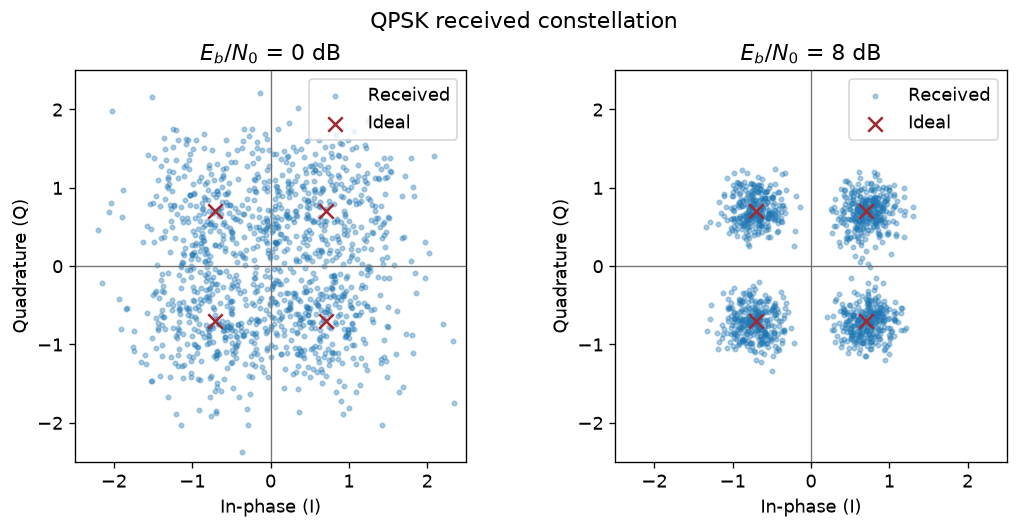

In [3]:
def add_awgn(symbols, eb_n0_db, rng):
    eb_n0 = 10 ** (eb_n0_db / 10)
    n0 = BIT_ENERGY / eb_n0
    sigma = np.sqrt(n0 / 2)
    noise_i = rng.normal(0, sigma, symbols.shape)
    noise_q = rng.normal(0, sigma, symbols.shape)
    return symbols + noise_i + 1j * noise_q


simulation_seed, plot_seed = np.random.SeedSequence(SEED).spawn(2)
rng = np.random.default_rng(simulation_seed)
plot_rng = np.random.default_rng(plot_seed)
bits = rng.integers(0, 2, size=N_BITS, dtype=np.uint8)
tx_symbols = map_bits(bits)
np.testing.assert_array_equal(decide_bits(tx_symbols), bits)

sample = tx_symbols[:1200]
figure, axes = plt.subplots(1, 2, figsize=(9, 4.3), layout="constrained")
for ax, db in zip(axes, (0, 8), strict=True):
    received = add_awgn(sample, db, plot_rng)
    ax.scatter(received.real, received.imag, s=7, alpha=0.35, label="Received")
    ax.scatter(
        ideal_symbols.real,
        ideal_symbols.imag,
        marker="x",
        s=75,
        color="#a12830",
        label="Ideal",
    )
    ax.axhline(0, color="0.45", linewidth=0.8)
    ax.axvline(0, color="0.45", linewidth=0.8)
    ax.set(
        title=rf"$E_b/N_0$ = {db} dB",
        xlabel="In-phase (I)",
        ylabel="Quadrature (Q)",
        xlim=(-2.5, 2.5),
        ylim=(-2.5, 2.5),
        aspect="equal",
    )
    ax.legend(loc="upper right")
figure.suptitle("QPSK received constellation")
plt.show()

## 3. 恢复比特，扫信噪比

每个点都用同一批发送比特，重新产生对应噪声。先判决回比特，再逐位比较。BER 是**错误比特数 / 总比特数**。如果一个符号的两位都出错，分子要加 2。

理论曲线从单轴推导。坐标离判决轴的距离是 $sqrt{E_b}$，除以噪声标准差 $sqrt{N_0/2}$ 后，跨过判决轴的概率是标准正态尾概率。I、Q 两路的每比特错误概率相同，所以 $P_b = Q(sqrt{2E_b/N_0}) = 	frac12operatorname{erfc}(sqrt{E_b/N_0})$。[QPSK 的理论 BER 公式](https://www.mathworks.com/help/comm/ug/analytical-expressions-used-in-berawgn-function-and-bit-error-rate-analysis.html#mpsk)

In [4]:
def theoretical_ber(eb_n0_db):
    eb_n0 = 10 ** (eb_n0_db / 10)
    return 0.5 * erfc(np.sqrt(eb_n0))


error_counts = []
for db in EB_N0_DB:
    rx_symbols = add_awgn(tx_symbols, db, rng)
    recovered_bits = decide_bits(rx_symbols)
    error_counts.append(np.count_nonzero(recovered_bits != bits))

error_counts = np.array(error_counts)
simulated_ber = error_counts / bits.size
expected_ber = theoretical_ber(EB_N0_DB)

print(" Eb/N0 (dB)   Errors / total bits    Simulated BER   Theory BER")
for db, errors, simulated, expected in zip(
    EB_N0_DB, error_counts, simulated_ber, expected_ber, strict=True
):
    print(f"{db:>10}   {errors:>6,} / {bits.size:,}      {simulated:>11.3e}   {expected:>10.3e}")

 Eb/N0 (dB)   Errors / total bits    Simulated BER   Theory BER
         0   31,526 / 400,000        7.881e-02    7.865e-02
         1   22,225 / 400,000        5.556e-02    5.628e-02
         2   15,131 / 400,000        3.783e-02    3.751e-02
         3    9,130 / 400,000        2.283e-02    2.288e-02
         4    4,954 / 400,000        1.239e-02    1.250e-02
         5    2,444 / 400,000        6.110e-03    5.954e-03
         6      946 / 400,000        2.365e-03    2.388e-03
         7      310 / 400,000        7.750e-04    7.727e-04
         8       58 / 400,000        1.450e-04    1.909e-04
         9       14 / 400,000        3.500e-05    3.363e-05
        10        2 / 400,000        5.000e-06    3.872e-06
        11        0 / 400,000        0.000e+00    2.613e-07
        12        1 / 400,000        2.500e-06    9.006e-09


## 4. 画曲线，处理零错误点

纵轴用对数尺度。每个圆点是一个观测到非零错误数的仿真结果，实线是理论值。

当 $N$ 个比特中观测到 0 个错误，BER 点估计为 0。对数轴无法画 0，图中以倒三角标出单侧 95% 二项上限 $1-0.05^{1/N}$。它来自 $(1-p)^N=0.05$。有限次试验的零错误无法证明链路永远不出错。

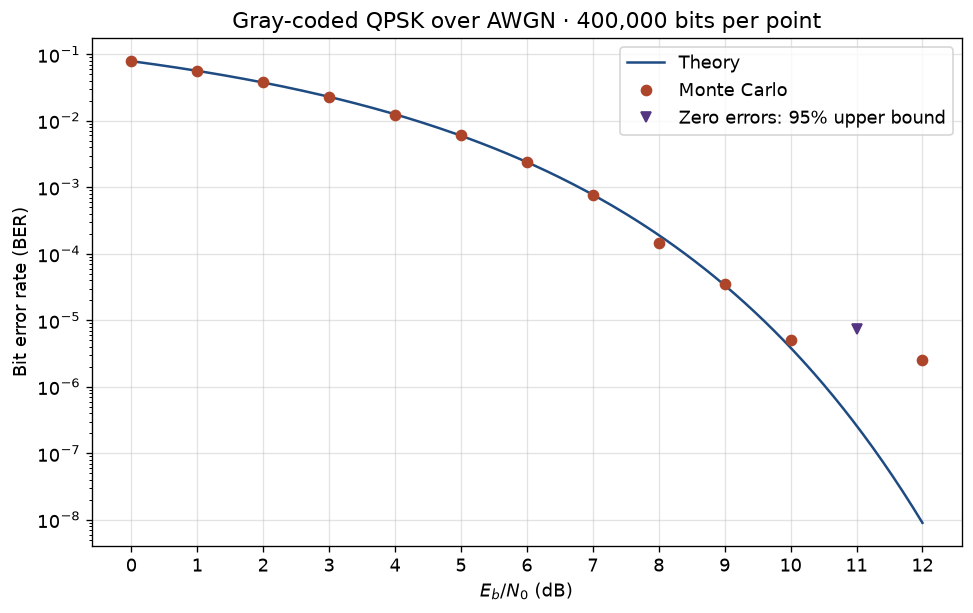

In [5]:
dense_db = np.linspace(EB_N0_DB[0], EB_N0_DB[-1], 241)
nonzero = error_counts > 0
zero_upper_bound = -np.expm1(np.log(0.05) / bits.size)

ber_figure, ax = plt.subplots(figsize=(8, 5), layout="constrained")
ax.semilogy(dense_db, theoretical_ber(dense_db), color="#1e4b82", label="Theory")
ax.semilogy(EB_N0_DB[nonzero], simulated_ber[nonzero], "o", color="#ad452a", label="Monte Carlo")
if np.any(~nonzero):
    ax.semilogy(
        EB_N0_DB[~nonzero],
        np.full(np.count_nonzero(~nonzero), zero_upper_bound),
        "v",
        color="#533581",
        label="Zero errors: 95% upper bound",
    )
ax.set(
    xlabel=r"$E_b/N_0$ (dB)",
    ylabel="Bit error rate (BER)",
    title=f"Gray-coded QPSK over AWGN · {bits.size:,} bits per point",
)
ax.set_xticks(EB_N0_DB)
ax.grid(True, which="major", alpha=0.35)
ax.legend()
plt.show()

# 需要把 BER 图放进作品集时，去掉下一行开头的 #，再运行此格。
# ber_figure.savefig("qpsk_ber.png", dpi=200)

默认参数下，0 dB 的仿真 BER 约为 0.07882，理论值约为 0.07865。11 dB 观测到 0 个错误，图上标出上限 $7.49\times10^{-6}$。12 dB 观测到 1 个错误，对应点估计 $2.5\times10^{-6}$。理论 BER 随信噪比下降，有限样本的误码计数会波动。换一个随机种子重跑，看看哪个高信噪比点观测到了错误。

## 5. 验收与动手题

上面的无噪声检查覆盖了四个 Gray 标签。下面再用理论误码计数做量级检查。预期错误数至少为 30 的点才使用正态近似，检查仿真计数是否落在理论均值的五个标准差以内。这个宽容差用于发现噪声归一化、符号映射或误码分母的错误。

1. 在纸上写出 `10` 的 I/Q 坐标，以及 I 分量跨零后接收端会输出什么。
2. 把 `N_BITS` 改成 `40_000`，从头运行，比较高信噪比端的计数和零错误上限。最后恢复原值。
3. 先预测每路噪声功率翻倍时，仿真相对理论会向哪侧偏移。把 `sigma` 临时乘以 `np.sqrt(2)` 验证。此时下方的计数检查预期会报错。观察完图后改回原公式。从横轴估读偏移，并用 `10 * np.log10(2)` 核对。

In [6]:
expected_errors = bits.size * expected_ber
count_std = np.sqrt(expected_errors * (1 - expected_ber))
enough_errors = expected_errors >= 30
deviation = np.abs(error_counts[enough_errors] - expected_errors[enough_errors])
assert np.all(deviation <= 5 * count_std[enough_errors]), "检查噪声归一化、映射和判决。"
print(f"理论误码计数的量级检查通过，共检查 {np.count_nonzero(enough_errors)} 个点。")

理论误码计数的量级检查通过，共检查 9 个点。
